In [2]:
import pandas as pd
import numpy as np

data = pd.read_csv("aqi_processed_data.csv")
print(data.head())
print(data.shape)
print(data.columns)
print(data.info())
print(data.describe())

              datetime  year  month  hour  day_of_week  temp_2m_c  \
0  2022-08-05 00:00:00  2022      8     0            4       26.2   
1  2022-08-05 01:00:00  2022      8     1            4       26.3   
2  2022-08-05 02:00:00  2022      8     2            4       26.3   
3  2022-08-05 03:00:00  2022      8     3            4       26.1   
4  2022-08-05 04:00:00  2022      8     4            4       26.0   

   humidity_percent  wind_speed_10m_kmh  wind_dir_10m  wind_gusts_kmh  ...  \
0                91                 6.8           205            12.2  ...   
1                92                 4.5           194            13.0  ...   
2                91                 4.0           185             8.3  ...   
3                91                 4.7           180             9.0  ...   
4                91                 7.2           198            13.0  ...   

   pm2_5_ugm3  pm10_ugm3  co_ugm3  no2_ugm3  so2_ugm3  o3_ugm3  dust_ugm3  \
0        15.3       23.7    382.0      

In [6]:
FORECAST_HORIZON = 1

data["target_pm25_1h"] = (
    data["pm2_5_ugm3"].shift(-FORECAST_HORIZON)
)
print(
    data[
        ["pm2_5_ugm3", "target_pm25_1h"]
    ].head(10)
)

   pm2_5_ugm3  target_pm25_1h
0        15.3            14.0
1        14.0            12.5
2        12.5            10.5
3        10.5            10.0
4        10.0            12.2
5        12.2            12.7
6        12.7            12.9
7        12.9            14.5
8        14.5            16.9
9        16.9            19.9


In [10]:
data.sort_index(inplace=True)

In [11]:
lag_hours = [1, 2, 3, 6, 12, 24, 48, 168]

for lag in lag_hours:
    data[f"pm25_lag_{lag}"] = (
        data["pm2_5_ugm3"].shift(lag)
    )

In [12]:
columns_to_check = [
    "pm2_5_ugm3",
    "pm25_lag_1",
    "pm25_lag_2",
    "pm25_lag_3",
    "pm25_lag_24",
    "pm25_lag_168",
    "target_pm25_1h"
]

print(data[columns_to_check].iloc[165:175])

     pm2_5_ugm3  pm25_lag_1  pm25_lag_2  pm25_lag_3  pm25_lag_24  \
165        21.7        20.5        20.9        20.1         20.8   
166        20.8        21.7        20.5        20.9         20.5   
167        20.3        20.8        21.7        20.5         21.6   
168        19.5        20.3        20.8        21.7         20.3   
169        19.6        19.5        20.3        20.8         18.7   
170        20.1        19.6        19.5        20.3         17.8   
171        20.7        20.1        19.6        19.5         19.7   
172        19.7        20.7        20.1        19.6         22.7   
173        21.0        19.7        20.7        20.1         24.2   
174        21.9        21.0        19.7        20.7         24.9   

     pm25_lag_168  target_pm25_1h  
165           NaN            20.8  
166           NaN            20.3  
167           NaN            19.5  
168          15.3            19.6  
169          14.0            20.1  
170          12.5            20.7  

In [13]:
lag_columns = [
    f"pm25_lag_{lag}" for lag in lag_hours
]

print(
    data[
        lag_columns + ["target_pm25_1h"]
    ].isnull().sum()
)

pm25_lag_1          1
pm25_lag_2          2
pm25_lag_3          3
pm25_lag_6          6
pm25_lag_12        12
pm25_lag_24        24
pm25_lag_48        48
pm25_lag_168      168
target_pm25_1h      1
dtype: int64


In [14]:
print(
    data[
        [
            "pm2_5_ugm3",
            "pm25_lag_1",
            "pm25_lag_2",
            "pm25_lag_3"
        ]
    ].head(5)
)

   pm2_5_ugm3  pm25_lag_1  pm25_lag_2  pm25_lag_3
0        15.3         NaN         NaN         NaN
1        14.0        15.3         NaN         NaN
2        12.5        14.0        15.3         NaN
3        10.5        12.5        14.0        15.3
4        10.0        10.5        12.5        14.0


In [16]:
model_features = [
    # Current and historical PM2.5
    "pm2_5_ugm3",
    "pm25_lag_1",
    "pm25_lag_2",
    "pm25_lag_3",
    "pm25_lag_6",
    "pm25_lag_12",
    "pm25_lag_24",
    "pm25_lag_48",
    "pm25_lag_168",

    # Time features
    "year",
    "month",
    "hour",
    "day_of_week",

    # Weather features
    "temp_2m_c",
    "humidity_percent",
    "wind_speed_10m_kmh",
    "wind_dir_10m",
    "wind_gusts_kmh",
    "wind_stagnation",
    "precipitation_mm",
    "pressure_msl_hpa",
    "solar_radiation_wm2",
    "cloud_cover_percent",

    # Other pollutants
    "pm10_ugm3",
    "co_ugm3",
    "no2_ugm3",
    "so2_ugm3",
    "o3_ugm3",
    "dust_ugm3",
    "aod",

    # Special conditions
    "festival_period",
    "crop_burning_season"
]

print("Number of model features:", len(model_features))

Number of model features: 32


In [17]:
required_columns = (
    model_features + ["target_pm25_1h"]
)

valid_rows = data[required_columns].notna().all(axis=1)

X = data.loc[valid_rows, model_features]
y = data.loc[valid_rows, "target_pm25_1h"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("First usable timestamp:", X.index.min())
print("Last usable timestamp:", X.index.max())

X shape: (28871, 32)
y shape: (28871,)
First usable timestamp: 168
Last usable timestamp: 29038


In [18]:
total_rows = len(X)

train_end = int(total_rows * 0.70)
validation_end = int(total_rows * 0.85)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_validation = X.iloc[train_end:validation_end]
y_validation = y.iloc[train_end:validation_end]

X_test = X.iloc[validation_end:]
y_test = y.iloc[validation_end:]

In [19]:
print("Training shape:", X_train.shape)
print("Validation shape:", X_validation.shape)
print("Test shape:", X_test.shape)

print("\nTraining period:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nValidation period:")
print(X_validation.index.min(), "to", X_validation.index.max())

print("\nTest period:")
print(X_test.index.min(), "to", X_test.index.max())

Training shape: (20209, 32)
Validation shape: (4331, 32)
Test shape: (4331, 32)

Training period:
168 to 20376

Validation period:
20377 to 24707

Test period:
24708 to 29038


In [20]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

baseline_predictions = X_validation["pm2_5_ugm3"]

baseline_mae = mean_absolute_error(
    y_validation,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        baseline_predictions
    )
)

baseline_r2 = r2_score(
    y_validation,
    baseline_predictions
)

print("Baseline validation results")
print("MAE:", round(baseline_mae, 3))
print("RMSE:", round(baseline_rmse, 3))
print("R²:", round(baseline_r2, 3))

Baseline validation results
MAE: 2.742
RMSE: 4.152
R²: 0.969


In [21]:
from sklearn.ensemble import RandomForestRegressor

random_forest = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=3,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

RandomForestRegressor(max_depth=15, max_features='sqrt', min_samples_leaf=3,
                      n_estimators=200, n_jobs=-1, random_state=42)

In [22]:
validation_predictions = random_forest.predict(
    X_validation
)

In [23]:
rf_mae = mean_absolute_error(
    y_validation,
    validation_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        validation_predictions
    )
)

rf_r2 = r2_score(
    y_validation,
    validation_predictions
)

print("Random Forest validation results")
print("MAE:", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))
print("R²:", round(rf_r2, 3))

Random Forest validation results
MAE: 3.4
RMSE: 5.567
R²: 0.944


In [24]:
comparison = pd.DataFrame({
    "Model": [
        "Persistence baseline",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        rf_rmse
    ],
    "R2": [
        baseline_r2,
        rf_r2
    ]
})

print(comparison)

                  Model       MAE      RMSE        R2
0  Persistence baseline  2.742461  4.152047  0.968952
1         Random Forest  3.399521  5.567464  0.944176


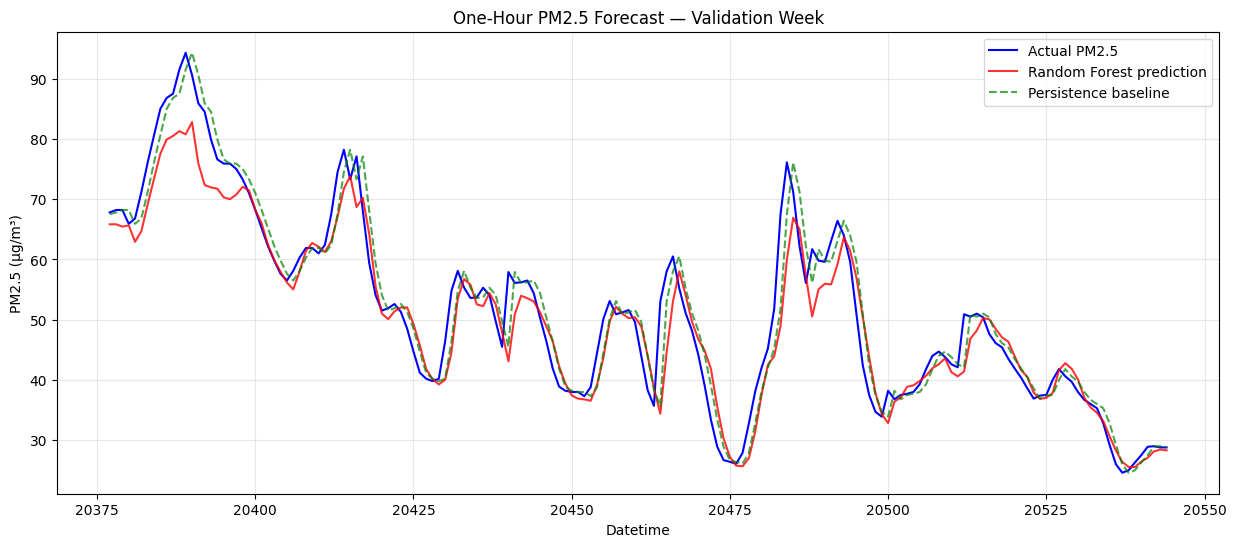

In [25]:
import matplotlib.pyplot as plt

display_hours = 24 * 7

plt.figure(figsize=(15, 6))

plt.plot(
    y_validation.index[:display_hours],
    y_validation.iloc[:display_hours],
    label="Actual PM2.5",
    color="blue"
)

plt.plot(
    y_validation.index[:display_hours],
    validation_predictions[:display_hours],
    label="Random Forest prediction",
    color="red",
    alpha=0.8
)

plt.plot(
    y_validation.index[:display_hours],
    baseline_predictions.iloc[:display_hours],
    label="Persistence baseline",
    color="green",
    linestyle="--",
    alpha=0.7
)

plt.title("One-Hour PM2.5 Forecast — Validation Week")
plt.xlabel("Datetime")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [28]:
training_predictions = random_forest.predict(X_train)

rf_train_mae = mean_absolute_error(
    y_train,
    training_predictions
)

rf_train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        training_predictions
    )
)

rf_train_r2 = r2_score(
    y_train,
    training_predictions
)

print("Random Forest training results")
print("MAE:", round(rf_train_mae, 3))
print("RMSE:", round(rf_train_rmse, 3))
print("R²:", round(rf_train_r2, 3))

Random Forest training results
MAE: 1.487
RMSE: 3.438
R²: 0.992


In [29]:
generalization_comparison = pd.DataFrame({
    "Dataset": [
        "Training",
        "Validation"
    ],
    "MAE": [
        rf_train_mae,
        rf_mae
    ],
    "RMSE": [
        rf_train_rmse,
        rf_rmse
    ],
    "R2": [
        rf_train_r2,
        rf_r2
    ]
})

print(generalization_comparison)

      Dataset       MAE      RMSE        R2
0    Training  1.487323  3.438314  0.991688
1  Validation  3.399521  5.567464  0.944176
